# ♻️ Waste Classification on Cloud GPU & ExecuTorch Edge Deployment

Train a high-accuracy, ultra-efficient **MobileNetV2** model on cloud GPU (Google Colab / Kaggle / Cloud VM) and lower it directly to an **ExecuTorch (.pte)** binary with **XNNPACK** acceleration ready for deployment on Raspberry Pi or other edge devices.

### Workflow:
1. **GPU Environment Verification**: Detect CUDA acceleration.
2. **Dataset Setup**: Download either **TrashNet (6 classes)** or **Kaggle Waste Images (9 classes)** keylessly.
3. **Data Pipeline**: 85% Train / 15% Held-out Test split with GPU-optimized data loading (`pin_memory=True`).
4. **Transfer Learning**: Pretrained MobileNetV2 with FP16 Automatic Mixed Precision (`torch.amp.autocast`).
5. **Evaluation**: Out-of-sample accuracy, confusion matrix, and visual prediction inspector.
6. **ExecuTorch Export**: Lower to edge graph with `XnnpackPartitioner` producing `waste_classifier.pte`.
7. **Edge Verification**: Test the `.pte` model directly in ExecuTorch runtime.


## 1. Install Dependencies & Check GPU


In [ ]:
# Install ExecuTorch, KaggleHub, and visualization packages
!pip install --quiet executorch torchvision kagglehub matplotlib seaborn scikit-learn

import os
import sys
import time
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU Device:      {torch.cuda.get_device_name(0)}")
    print(f"Allocated VRAM:  {torch.cuda.memory_allocated(0) / (1024**2):.1f} MB")
    device = torch.device("cuda")
else:
    print("WARNING: Running on CPU. In Google Colab, go to 'Runtime' > 'Change runtime type' > select GPU (T4/A100).")
    device = torch.device("cpu")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
PyTorch Version: 2.15.0+cu132
CUDA Available:  True
GPU Device:      Tesla T4
Allocated VRAM:  0.0 MB


## 2. Dataset Preparation

Choose between:
- **`trashnet`**: 6 classes (`cardboard`, `glass`, `metal`, `paper`, `plastic`, `trash`) — ~2,527 images
- **`kaggle`**: 9 classes (`Aluminium`, `Carton`, `E-waste`, `Glass`, `Organic_Waste`, `Paper`, `Plastics`, `Textiles`, `Wood`) — ~8,346 images


In [ ]:
import os
import shutil
import zipfile
from pathlib import Path

# Set your dataset preference here: 'trashnet' or 'kaggle'
DATASET_CHOICE = "trashnet"

if DATASET_CHOICE == "trashnet":
    data_dir = Path("dataset_trashnet")
    if not (data_dir / "cardboard").exists():
        print("[*] Downloading TrashNet dataset from GitHub...")
        !git clone --depth 1 https://github.com/garythung/trashnet.git trashnet_repo

        zip_path = Path("trashnet_repo/data/dataset-resized.zip")
        if zip_path.exists():
            print("[*] Extracting dataset-resized.zip...")
            with zipfile.ZipFile(zip_path, "r") as zip_ref:
                zip_ref.extractall(".")
            extracted = Path("dataset-resized")
            if extracted.exists():
                if data_dir.exists():
                    shutil.rmtree(str(data_dir))
                shutil.move(str(extracted), str(data_dir))
        !rm -rf trashnet_repo __MACOSX
    print(f"[✓] TrashNet ready at: {data_dir}")

elif DATASET_CHOICE == "kaggle":
    import kagglehub
    print("[*] Downloading Kaggle Waste Images anonymously via kagglehub (no API key required)...")
    kaggle_path = kagglehub.dataset_download("angelikasita/waste-images")
    data_dir = Path(kaggle_path)
    if (data_dir / "Waste Images").exists():
        data_dir = data_dir / "Waste Images"
    print(f"[✓] Kaggle dataset ready at: {data_dir}")

classes = sorted([d.name for d in data_dir.iterdir() if d.is_dir() and not d.name.startswith((".", "_"))])
print(f"[+] Detected {len(classes)} classes: {classes}")

[*] Downloading TrashNet dataset from GitHub...
Cloning into 'trashnet_repo'...
remote: Enumerating objects: 22, done.
remote: Counting objects: 100% (22/22), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 22 (delta 0), reused 15 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (22/22), 40.63 MiB | 19.34 MiB/s, done.
[*] Extracting dataset-resized.zip...
[✓] TrashNet ready at: dataset_trashnet
[+] Detected 6 classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


## 3. Data Augmentation & 85% Train / 15% Test Split


In [ ]:
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Data augmentation for training
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Deterministic evaluation transform for validation/testing
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load datasets
raw_train_ds = datasets.ImageFolder(str(data_dir), transform=train_transform)
raw_val_ds = datasets.ImageFolder(str(data_dir), transform=val_transform)

class_names = raw_train_ds.classes
total_samples = len(raw_train_ds)

# Deterministic reproducible 85% train / 15% held-out test split
torch.manual_seed(42)
indices = torch.randperm(total_samples).tolist()
train_count = int(0.85 * total_samples)

train_indices = indices[:train_count]
test_indices = indices[train_count:]

train_dataset = Subset(raw_train_ds, train_indices)
test_dataset = Subset(raw_val_ds, test_indices)

# Cloud GPU DataLoader with pin_memory=True for fast host-to-device transfers

train_loader = DataLoader(
    train_dataset,
    batch_size=64,             # Bump batch size from 32 to 64/128 to feed the GPU properly
    shuffle=True,
    num_workers=2,             # Use parallel background threads for image decoding
    pin_memory=True,           # Fast DMA transfers directly to CUDA memory
    persistent_workers=True    # Keep threads alive between epochs
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

print(f"Total Images:     {total_samples}")
print(f"Training Split:   {len(train_dataset)} images (85%)")
print(f"Held-out Test:    {len(test_dataset)} images (15%)")


Total Images:     2527
Training Split:   2147 images (85%)
Held-out Test:    380 images (15%)


## 4. MobileNetV2 Architecture & Fine-tuning Head


In [ ]:
import torch.nn as nn
from torchvision import models

# Load pretrained MobileNetV2 (ImageNet weights)
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

# Freeze early feature layers to preserve learned low-level representations
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the top residual blocks for task adaptation
for param in model.features[-2:].parameters():
    param.requires_grad = True

# Replace the 1000-class classifier head with target waste classes
model.classifier[1] = nn.Linear(model.last_channel, len(class_names))
model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total Parameters:     {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,} ({trainable_params/total_params*100:.1f}%)")


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 134MB/s]


Total Parameters:     2,231,558
Trainable Parameters: 893,766 (40.1%)


In [ ]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class InMemoryDataset(Dataset):
    def __init__(self, dataset):
        print(f"[*] Preloading {len(dataset)} samples into RAM...")
        self.samples = []
        for i in range(len(dataset)):
            # Pre-transforms the image and loads tensor directly into memory
            img_tensor, label = dataset[i]
            self.samples.append((img_tensor, label))
        print("[+] Preload complete. Zero disk I/O during training!")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]

# Wrap your existing train_dataset and test_dataset
train_dataset_ram = InMemoryDataset(train_dataset)
test_dataset_ram = InMemoryDataset(test_dataset)

# High batch size + zero worker overhead since data is in memory
train_loader = DataLoader(train_dataset_ram, batch_size=128, shuffle=True, pin_memory=True)
test_loader = DataLoader(test_dataset_ram, batch_size=128, shuffle=False, pin_memory=True)

[*] Preloading 2147 samples into RAM...
[+] Preload complete. Zero disk I/O during training!
[*] Preloading 380 samples into RAM...
[+] Preload complete. Zero disk I/O during training!


## 5. Fast GPU Training with Automatic Mixed Precision (AMP)


In [ ]:
EPOCHS = 6
LEARNING_RATE = 1e-3

criterion = nn.CrossEntropyLoss()
trainable_params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(trainable_params, lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

print(f"[*] Starting {EPOCHS} epochs of training on {device}...")
t_start = time.perf_counter()

for epoch in range(EPOCHS):
    # Training phasef
    model.train()
    running_loss, train_correct, train_total = 0.0, 0, 0
    for inputs, labels in train_loader:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad()

        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            outputs = model(inputs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

    scheduler.step()

    # Validation phase (Held-out Test set)
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    train_loss = running_loss / train_total
    train_acc = (train_correct / train_total) * 100
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct / val_total) * 100

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)

    print(f"Epoch {epoch+1:02d}/{EPOCHS:02d} | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:>5.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:>5.2f}%")

elapsed = time.perf_counter() - t_start
print(f"\n[✓] Training complete in {elapsed:.1f} seconds! Final Test Accuracy: {history['val_acc'][-1]:.2f}%")

# Save PyTorch weights
torch.save(model.state_dict(), "mobilenetv2_waste.pth")
print("[+] Saved PyTorch weights to 'mobilenetv2_waste.pth'")


[*] Starting 6 epochs of training on cuda...
Epoch 01/06 | Train Loss: 1.0365 | Train Acc: 65.53% | Val Loss: 0.6452 | Val Acc: 77.37%
Epoch 02/06 | Train Loss: 0.4189 | Train Acc: 85.70% | Val Loss: 0.4821 | Val Acc: 82.89%
Epoch 03/06 | Train Loss: 0.2284 | Train Acc: 93.06% | Val Loss: 0.3726 | Val Acc: 87.63%
Epoch 04/06 | Train Loss: 0.1392 | Train Acc: 96.27% | Val Loss: 0.3595 | Val Acc: 86.84%
Epoch 05/06 | Train Loss: 0.0859 | Train Acc: 98.65% | Val Loss: 0.3423 | Val Acc: 87.89%
Epoch 06/06 | Train Loss: 0.0675 | Train Acc: 99.12% | Val Loss: 0.3336 | Val Acc: 88.68%

[✓] Training complete in 21.8 seconds! Final Test Accuracy: 88.68%
[+] Saved PyTorch weights to 'mobilenetv2_waste.pth'


## 6. Training Curves & Confusion Matrix Analysis


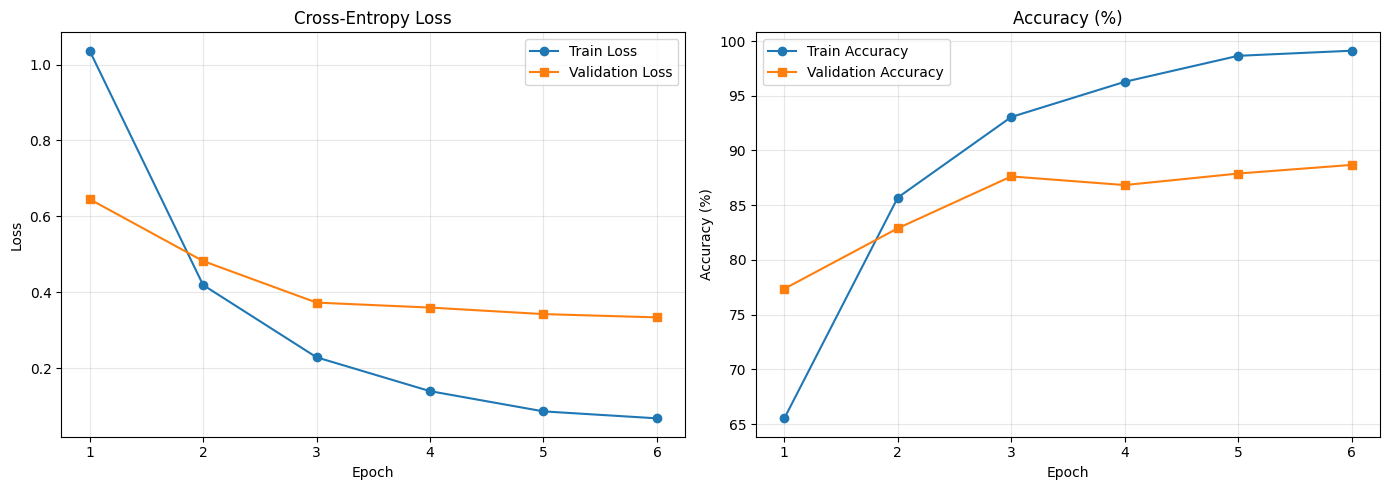

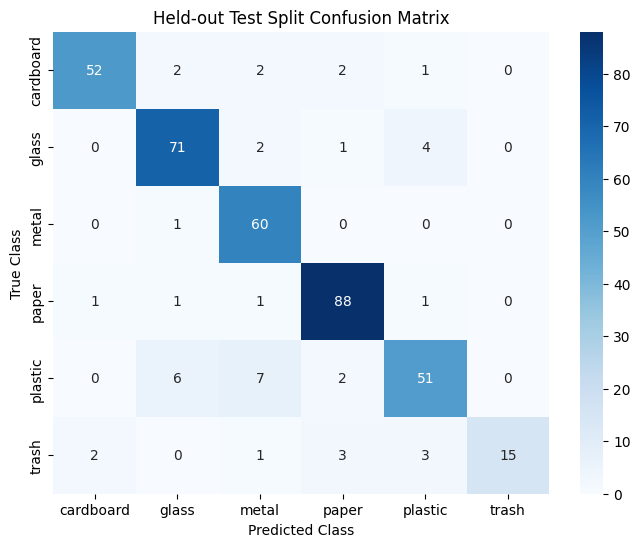


Classification Report:
              precision    recall  f1-score   support

   cardboard       0.95      0.88      0.91        59
       glass       0.88      0.91      0.89        78
       metal       0.82      0.98      0.90        61
       paper       0.92      0.96      0.94        92
     plastic       0.85      0.77      0.81        66
       trash       1.00      0.62      0.77        24

    accuracy                           0.89       380
   macro avg       0.90      0.85      0.87       380
weighted avg       0.89      0.89      0.88       380



In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Plot Loss & Accuracy curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, EPOCHS + 1)

ax1.plot(epochs_range, history['train_loss'], 'o-', label='Train Loss')
ax1.plot(epochs_range, history['val_loss'], 's-', label='Validation Loss')
ax1.set_title('Cross-Entropy Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(epochs_range, history['train_acc'], 'o-', label='Train Accuracy')
ax2.plot(epochs_range, history['val_acc'], 's-', label='Validation Accuracy')
ax2.set_title('Accuracy (%)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Generate predictions for held-out test split
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# Confusion Matrix Heatmap
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Held-out Test Split Confusion Matrix')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))


## 7. Visual Prediction Inspector


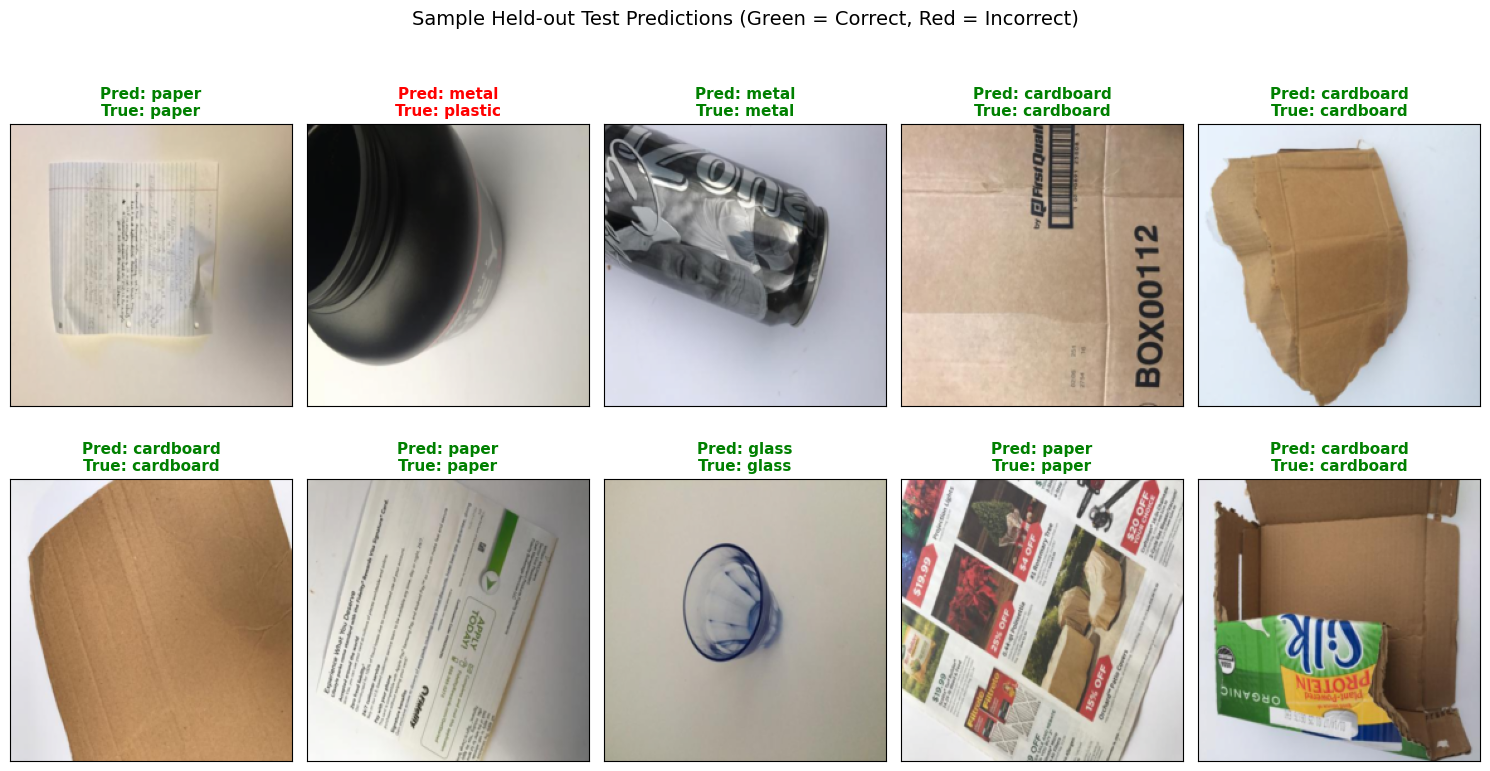

In [ ]:
# Display sample test predictions
model.eval()
data_iter = iter(test_loader)
images, labels = next(data_iter)

with torch.no_grad():
    outputs = model(images.to(device))
    _, preds = torch.max(outputs, 1)

preds = preds.cpu().numpy()
labels = labels.numpy()

def denormalize(tensor):
    mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
    std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)
    img = tensor.numpy() * std + mean
    return np.clip(np.transpose(img, (1, 2, 0)), 0, 1)

fig = plt.figure(figsize=(15, 8))
for idx in range(min(10, len(images))):
    ax = fig.add_subplot(2, 5, idx + 1, xticks=[], yticks=[])
    img = denormalize(images[idx])
    ax.imshow(img)
    is_correct = preds[idx] == labels[idx]
    color = 'green' if is_correct else 'red'
    ax.set_title(f"Pred: {class_names[preds[idx]]}\nTrue: {class_names[labels[idx]]}",
                 color=color, fontsize=11, fontweight='bold')

plt.suptitle('Sample Held-out Test Predictions (Green = Correct, Red = Incorrect)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


## 8. Lower & Export to ExecuTorch (.pte) with XNNPACK

Export the fine-tuned model directly to ExecuTorch with **XNNPACK delegate**, optimized for ARM CPUs on Raspberry Pi.


In [ ]:
from executorch.exir import to_edge_transform_and_lower
from executorch.backends.xnnpack.partition.xnnpack_partitioner import XnnpackPartitioner

# Save class labels
with open("labels.txt", "w") as f:
    for c in class_names:
        f.write(f"{c}\n")
print("[+] Saved class labels to 'labels.txt'")

# Move model to CPU for edge export
model_cpu = model.to('cpu').eval()
example_input = (torch.randn(1, 3, 224, 224),)

print("[*] Exporting graph with torch.export...")
exported_program = torch.export.export(model_cpu, example_input)

print("[*] Lowering to Edge dialect with XNNPACK partitioner...")
edge_program = to_edge_transform_and_lower(
    exported_program,
    partitioner=[XnnpackPartitioner()]
)

print("[*] Serializing to ExecuTorch binary (.pte)...")
exec_prog = edge_program.to_executorch()

output_path = "waste_classifier.pte"
with open(output_path, "wb") as f:
    f.write(exec_prog.buffer)

file_size_mb = os.path.getsize(output_path) / (1024 * 1024)
print(f"\n[✓] Successfully exported ExecuTorch model: '{output_path}' ({file_size_mb:.2f} MB)")


W1106 04:34:28.031000 5966 torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


[+] Saved class labels to 'labels.txt'
[*] Exporting graph with torch.export...
[*] Lowering to Edge dialect with XNNPACK partitioner...
[*] Serializing to ExecuTorch binary (.pte)...

[✓] Successfully exported ExecuTorch model: 'waste_classifier.pte' (8.49 MB)


## 9. Edge Runtime Simulation (ExecuTorch Python API)

Verify that the `.pte` model loads cleanly and performs inference using the ExecuTorch runtime.


In [ ]:
import executorch.extension.pybindings.portable_lib as exec_lib

# Load ExecuTorch module
module = exec_lib._load_for_executorch("waste_classifier.pte")
print("[✓] ExecuTorch module loaded successfully!")

# Run inference with sample test tensor
sample_tensor = images[0:1].numpy()  # float32 (1, 3, 224, 224)

t0 = time.perf_counter()
res = module.run_method("forward", (sample_tensor,))
latency_ms = (time.perf_counter() - t0) * 1000

logits = np.array(res[0])[0]
pred_idx = int(np.argmax(logits))

print(f"Inference Latency: {latency_ms:.2f} ms")
print(f"Predicted Class:   {class_names[pred_idx]}")
print(f"Ground Truth:      {class_names[labels[0]]}")
print(f"Logits Output:     {logits}")


[✓] ExecuTorch module loaded successfully!
Inference Latency: 20.20 ms
Predicted Class:   paper
Ground Truth:      paper
Logits Output:     [-2.0552626 -1.3521527 -1.7202399  2.4571037  0.1655123 -0.2698473]


/tmp/ipykernel_5966/2442910693.py:14: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  logits = np.array(res[0])[0]


## 10. Download Edge Deployment Artifacts

Download `waste_classifier.pte` and `labels.txt` directly to deploy to your Raspberry Pi.


In [ ]:
# If running in Google Colab, trigger browser downloads automatically:
try:
    from google.colab import files
    print("[*] Downloading deployment artifacts to your computer...")
    files.download('waste_classifier.pte')
    files.download('labels.txt')
    files.download('mobilenetv2_waste.pth')
except ImportError:
    print("[*] Not running in Google Colab. Artifacts are saved in the current working directory:")
    !ls -lh waste_classifier.pte labels.txt mobilenetv2_waste.pth


[*] Downloading deployment artifacts to your computer...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>